# 1. Project Introduction

## Movie Recommendation System Using Collaborative Filtering and SVD

### Introduction

Recommendation systems are widely used by digital platforms to suggest products, movies, music, and other content based on users' preferences and interests.

In this project, I developed a Movie Recommendation System using the MovieLens 100K dataset. The aim was to explore how machine learning techniques can identify patterns in user ratings and use those patterns to recommend movies that users may enjoy.

I implemented and explored three recommendation approaches:

- **User-Based Collaborative Filtering:** Finds users with similar movie preferences and uses their ratings to make recommendations.
- **Item-Based Collaborative Filtering:** Identifies movies with similar rating patterns to recommend related movies.
- **Singular Value Decomposition (SVD):** Applies matrix factorization to discover hidden relationships between users and movies and predict movie ratings.

The project also explores data analysis, data preparation, similarity calculations, rating prediction, and model evaluation.

### Project Objectives

1. Understand the structure of a movie-rating dataset.
2. Explore user rating patterns and movie preferences.
3. Build user-based and item-based recommendation systems.
4. Implement matrix factorization using SVD.
5. Evaluate and compare recommendation approaches.
6. Identify the strengths and limitations of each approach.

### Dataset

The project uses the **MovieLens 100K dataset**, which contains 100,000 ratings from 943 users across 1,682 movies.

### Tools and Libraries

Python, Pandas, NumPy, Matplotlib, Scikit-learn, Scikit-Surprise, and Google Colab.

### Importing Packages

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

### Loading dataset

In [2]:
ratings = pd.read_csv(
    '/content/u.data',
    sep='\t',
    names=['user_id', 'movie_id', 'rating', 'timestamp']
)

### Exploratory Data Analysis (EDA)

In [3]:
ratings.head()

,user_id,movie_id,rating,timestamp
0,196,242,3,881250949
1,186,302,3,891717742
2,22,377,1,878887116
3,244,51,2,880606923
4,166,346,1,886397596


In [4]:
ratings.shape

(100000, 4)

In [5]:
ratings.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 4 columns):
 #   Column     Non-Null Count   Dtype
---  ------     --------------   -----
 0   user_id    100000 non-null  int64
 1   movie_id   100000 non-null  int64
 2   rating     100000 non-null  int64
 3   timestamp  100000 non-null  int64
dtypes: int64(4)
memory usage: 3.1 MB


In [6]:
ratings.isnull().sum()

,0
user_id,0
movie_id,0
rating,0
timestamp,0


### Checking for total numbers of Ratings, users ans movies

In [7]:
print("Total number of ratings:", len(ratings))

print("Total number of users:", ratings['user_id'].nunique())

print("Total number of movies:", ratings['movie_id'].nunique())

Total number of ratings: 100000
Total number of users: 943
Total number of movies: 1682


### Analysing the distribution of movie ratings.

In [8]:
rating_distribution = ratings['rating'].value_counts().sort_index()

print(rating_distribution)

rating
1     6110
2    11370
3    27145
4    34174
5    21201
Name: count, dtype: int64


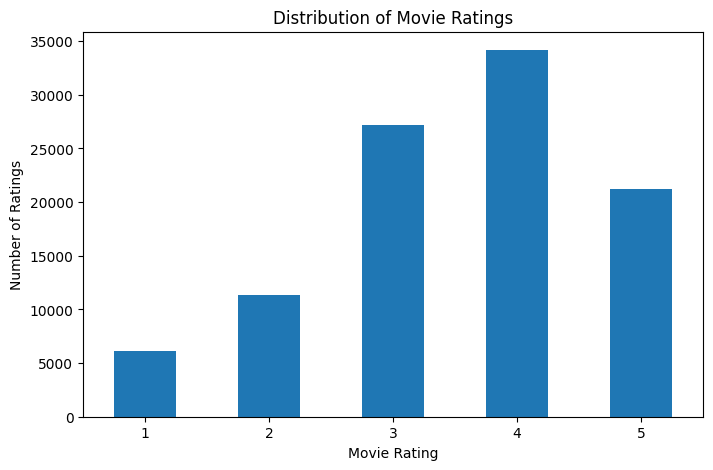

In [9]:
plt.figure(figsize=(8, 5))

rating_distribution.plot(kind='bar')

plt.title('Distribution of Movie Ratings')
plt.xlabel('Movie Rating')
plt.ylabel('Number of Ratings')

plt.xticks(rotation=0)
plt.show()

### Identifing the most-rated movies.

In [10]:
movie_rating_counts = ratings['movie_id'].value_counts()

print(movie_rating_counts.head(10))

movie_id
50     583
258    509
100    508
181    507
294    485
286    481
288    478
1      452
300    431
121    429
Name: count, dtype: int64


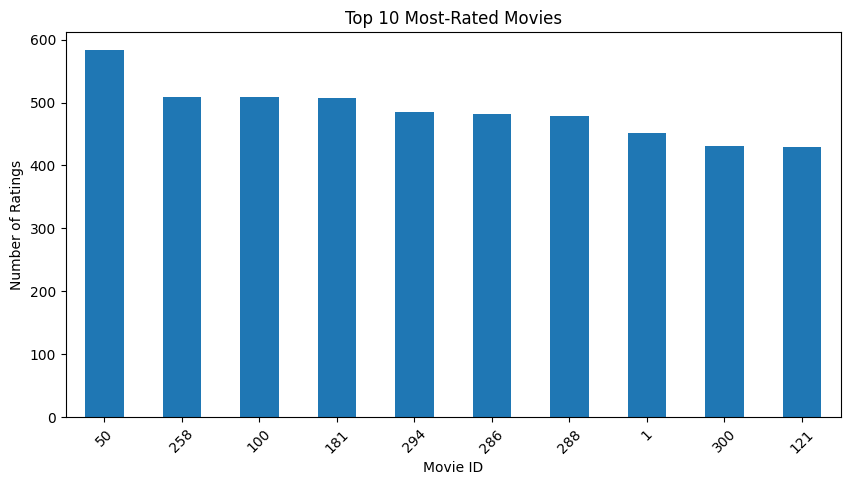

In [11]:
top_10_movies = movie_rating_counts.head(10)

plt.figure(figsize=(10, 5))

top_10_movies.plot(kind='bar')

plt.title('Top 10 Most-Rated Movies')
plt.xlabel('Movie ID')
plt.ylabel('Number of Ratings')

plt.xticks(rotation=45)
plt.show()

### Average Ratings

In [12]:
average_movie_ratings = ratings.groupby('movie_id')['rating'].mean()

print(average_movie_ratings.head(10))

movie_id
1     3.878319
2     3.206107
3     3.033333
4     3.550239
5     3.302326
6     3.576923
7     3.798469
8     3.995434
9     3.896321
10    3.831461
Name: rating, dtype: float64


In [13]:
sorted_average_ratings = average_movie_ratings.sort_values(ascending=False)

print(sorted_average_ratings.head(10))

movie_id
1189    5.0
1500    5.0
1201    5.0
1293    5.0
1653    5.0
1122    5.0
814     5.0
1467    5.0
1536    5.0
1599    5.0
Name: rating, dtype: float64


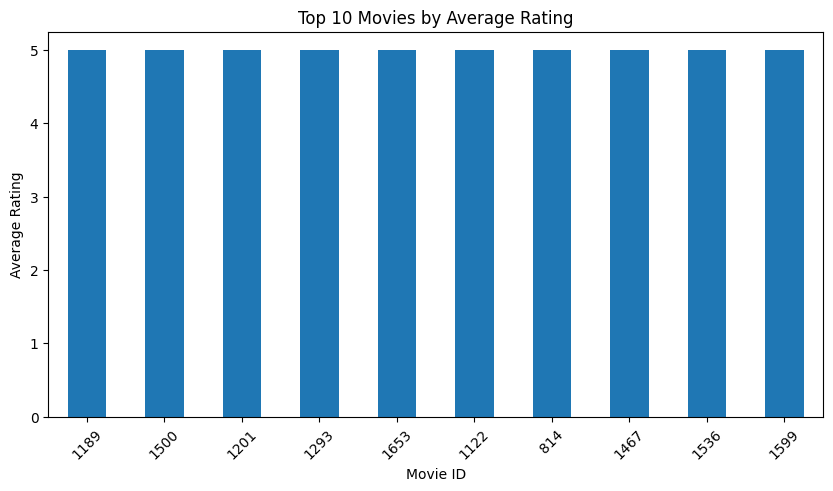

In [14]:
top_10_average = sorted_average_ratings.head(10)

plt.figure(figsize=(10, 5))

top_10_average.plot(kind='bar')

plt.title('Top 10 Movies by Average Rating')
plt.xlabel('Movie ID')
plt.ylabel('Average Rating')

plt.xticks(rotation=45)
plt.show()

### Distribution of Movie Ratings

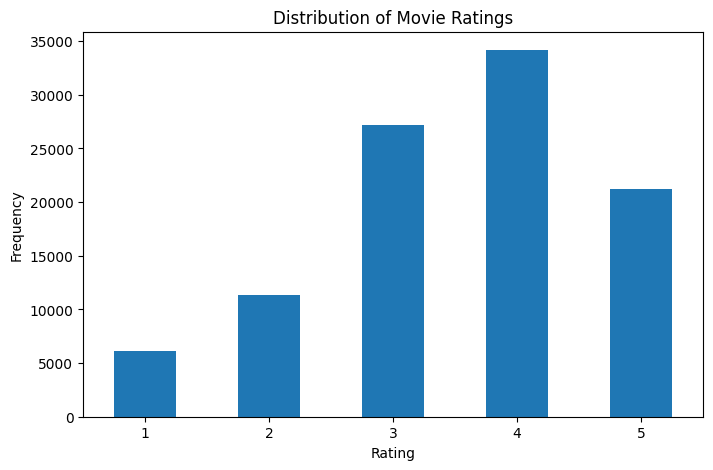

In [15]:
plt.figure(figsize=(8, 5))

ratings['rating'].value_counts().sort_index().plot(kind='bar')

plt.title('Distribution of Movie Ratings')
plt.xlabel('Rating')
plt.ylabel('Frequency')
plt.xticks(rotation=0)

plt.show()

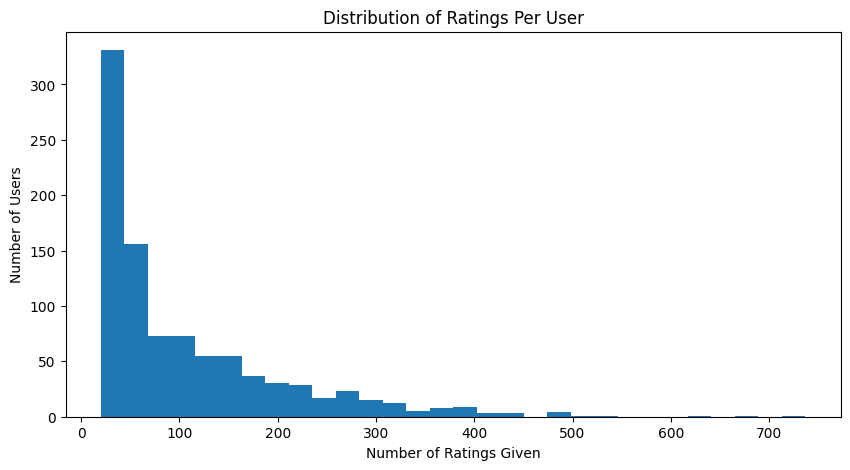

In [16]:
user_activity = ratings['user_id'].value_counts()

plt.figure(figsize=(10, 5))

plt.hist(user_activity, bins=30)

plt.title('Distribution of Ratings Per User')
plt.xlabel('Number of Ratings Given')
plt.ylabel('Number of Users')

plt.show()

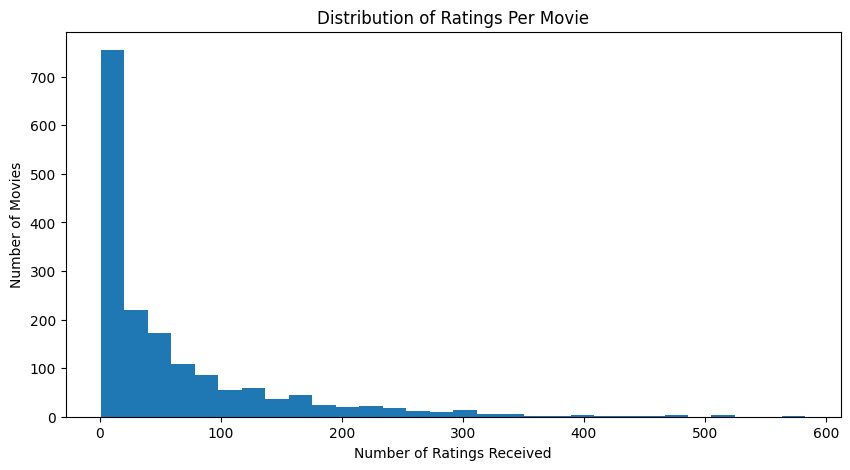

In [17]:
movie_popularity = ratings['movie_id'].value_counts()

plt.figure(figsize=(10, 5))

plt.hist(movie_popularity, bins=30)

plt.title('Distribution of Ratings Per Movie')
plt.xlabel('Number of Ratings Received')
plt.ylabel('Number of Movies')

plt.show()

In [18]:
print("Average ratings per user:", user_activity.mean())

print("Maximum ratings by one user:", user_activity.max())

print("Minimum ratings by one user:", user_activity.min())

Average ratings per user: 106.04453870625663
Maximum ratings by one user: 737
Minimum ratings by one user: 20


In [19]:
ratings.isnull().sum()

,0
user_id,0
movie_id,0
rating,0
timestamp,0


In [20]:
ratings.duplicated().sum()

np.int64(0)

In [21]:
ratings.duplicated(subset=['user_id', 'movie_id']).sum()

np.int64(0)

###  Data Preparation and Train-Test Split

Before building the recommendation models, the dataset was prepared for machine learning.

The ratings dataset was divided into two subsets:

- **Training set (80%):** Used to train the recommendation algorithms.
- **Testing set (20%):** Used to evaluate how well the models perform on unseen ratings.

The split was performed using Scikit-learn's `train_test_split()` function with a random state of 42 to ensure reproducibility.

This separation helps assess how well the recommendation system can generalize beyond the ratings it was trained on.

### Creating User Item Matrix

In [23]:
user_item_matrix = ratings.pivot_table(
    index='user_id',
    columns='movie_id',
    values='rating'
)

In [24]:
user_item_matrix.head()

movie_id,1,2,3,4,5,6,7,8,9,10,...,1673,1674,1675,1676,1677,1678,1679,1680,1681,1682
user_id,,,,,,,,,,,,,,,,,,,,,
1,5.0,3.0,4.0,3.0,3.0,5.0,4.0,1.0,5.0,3.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,4.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,4.0,3.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [25]:
print("Matrix shape:", user_item_matrix.shape)

print("Total users:", user_item_matrix.shape[0])

print("Total movies:", user_item_matrix.shape[1])

Matrix shape: (943, 1682)
Total users: 943
Total movies: 1682


In [26]:
user_item_matrix.isnull().sum().sum()

np.int64(1486126)

In [27]:
total_cells = user_item_matrix.size

missing_cells = user_item_matrix.isnull().sum().sum()

sparsity = (missing_cells / total_cells) * 100

print("Total cells:", total_cells)
print("Missing cells:", missing_cells)
print("Matrix sparsity:", sparsity, "%")

Total cells: 1586126
Missing cells: 1486126
Matrix sparsity: 93.69533063577546 %


# 7. User-Based Collaborative Filtering

User-Based Collaborative Filtering is a recommendation technique that identifies users with similar movie preferences and uses their ratings to recommend movies to one another.

In this project, cosine similarity was used to measure how similar users were based on their movie-rating patterns.

The process involved:

1. Representing users through their movie ratings.
2. Filling missing ratings with zero for similarity calculations.
3. Calculating cosine similarity between users.
4. Identifying the most similar users.
5. Using ratings from similar users to score movies.
6. Recommending movies the target user had not previously rated.

User-Based Collaborative Filtering helps personalize recommendations by identifying users with similar interests.

**Target user:** User 196.

### Import cosine similarity

In [28]:
from sklearn.metrics.pairwise import cosine_similarity


In [29]:
user_item_filled = user_item_matrix.fillna(0)

In [30]:
user_similarity = cosine_similarity(user_item_filled)

In [31]:
user_similarity_df = pd.DataFrame(
    user_similarity,
    index=user_item_matrix.index,
    columns=user_item_matrix.index
)

In [32]:
user_similarity_df.head()

user_id,1,2,3,4,5,6,7,8,9,10,...,934,935,936,937,938,939,940,941,942,943
user_id,,,,,,,,,,,,,,,,,,,,,
1,1.000000,0.166931,0.047460,0.064358,0.378475,0.430239,0.440367,0.319072,0.078138,0.376544,...,0.369527,0.119482,0.274876,0.189705,0.197326,0.118095,0.314072,0.148617,0.179508,0.398175
2,0.166931,1.000000,0.110591,0.178121,0.072979,0.245843,0.107328,0.103344,0.161048,0.159862,...,0.156986,0.307942,0.358789,0.424046,0.319889,0.228583,0.226790,0.161485,0.172268,0.105798
3,0.047460,0.110591,1.000000,0.344151,0.021245,0.072415,0.066137,0.083060,0.061040,0.065151,...,0.031875,0.042753,0.163829,0.069038,0.124245,0.026271,0.161890,0.101243,0.133416,0.026556
4,0.064358,0.178121,0.344151,1.000000,0.031804,0.068044,0.091230,0.188060,0.101284,0.060859,...,0.052107,0.036784,0.133115,0.193471,0.146058,0.030138,0.196858,0.152041,0.170086,0.058752
5,0.378475,0.072979,0.021245,0.031804,1.000000,0.237286,0.373600,0.248930,0.056847,0.201427,...,0.338794,0.080580,0.094924,0.079779,0.148607,0.071459,0.239955,0.139595,0.152497,0.313941


In [33]:
user_similarity_df.head()

user_id,1,2,3,4,5,6,7,8,9,10,...,934,935,936,937,938,939,940,941,942,943
user_id,,,,,,,,,,,,,,,,,,,,,
1,1.000000,0.166931,0.047460,0.064358,0.378475,0.430239,0.440367,0.319072,0.078138,0.376544,...,0.369527,0.119482,0.274876,0.189705,0.197326,0.118095,0.314072,0.148617,0.179508,0.398175
2,0.166931,1.000000,0.110591,0.178121,0.072979,0.245843,0.107328,0.103344,0.161048,0.159862,...,0.156986,0.307942,0.358789,0.424046,0.319889,0.228583,0.226790,0.161485,0.172268,0.105798
3,0.047460,0.110591,1.000000,0.344151,0.021245,0.072415,0.066137,0.083060,0.061040,0.065151,...,0.031875,0.042753,0.163829,0.069038,0.124245,0.026271,0.161890,0.101243,0.133416,0.026556
4,0.064358,0.178121,0.344151,1.000000,0.031804,0.068044,0.091230,0.188060,0.101284,0.060859,...,0.052107,0.036784,0.133115,0.193471,0.146058,0.030138,0.196858,0.152041,0.170086,0.058752
5,0.378475,0.072979,0.021245,0.031804,1.000000,0.237286,0.373600,0.248930,0.056847,0.201427,...,0.338794,0.080580,0.094924,0.079779,0.148607,0.071459,0.239955,0.139595,0.152497,0.313941


### Identify Users with Similar Preferences

In [34]:
target_user = 196

In [35]:
similar_users = user_similarity_df[target_user].sort_values(
    ascending=False
)

print(similar_users.head(10))

user_id
196    1.000000
579    0.340097
591    0.326487
306    0.310731
523    0.290764
336    0.266866
860    0.261372
19     0.259553
354    0.251847
651    0.251688
Name: 196, dtype: float64


In [36]:
similar_users = similar_users.drop(target_user)


In [37]:
top_similar_users = similar_users.head(10)

print(top_similar_users)

user_id
579    0.340097
591    0.326487
306    0.310731
523    0.290764
336    0.266866
860    0.261372
19     0.259553
354    0.251847
651    0.251688
692    0.249010
Name: 196, dtype: float64


In [38]:
similar_users_ratings = user_item_matrix.loc[top_similar_users.index]

similar_users_ratings.head()

movie_id,1,2,3,4,5,6,7,8,9,10,...,1673,1674,1675,1676,1677,1678,1679,1680,1681,1682
user_id,,,,,,,,,,,,,,,,,,,,,
579,4.0,NaN,NaN,2.0,NaN,NaN,3.0,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
591,NaN,NaN,NaN,4.0,NaN,NaN,NaN,3.0,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
306,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
523,5.0,NaN,4.0,NaN,NaN,NaN,NaN,5.0,4.0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
336,3.0,NaN,1.0,4.0,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [39]:
top_similar_users

,196
user_id,
579,0.340097
591,0.326487
306,0.310731
523,0.290764
336,0.266866
860,0.261372
19,0.259553
354,0.251847
651,0.251688


In [40]:
recommended_movies = similar_users_ratings.mean(axis=0)

print(recommended_movies.head(10))

movie_id
1     4.0
2     NaN
3     2.5
4     3.6
5     NaN
6     NaN
7     3.5
8     4.5
9     3.5
10    5.0
dtype: float64


In [41]:
recommended_movies = recommended_movies.sort_values(ascending=False)

print(recommended_movies.head(10))

movie_id
19      5.0
20      5.0
1466    5.0
1472    5.0
1251    5.0
57      5.0
64      5.0
59      5.0
60      5.0
61      5.0
dtype: float64


In [42]:
recommended_movies.head(10)

,0
movie_id,
19,5.0
20,5.0
1466,5.0
1472,5.0
1251,5.0
57,5.0
64,5.0
59,5.0
60,5.0


In [43]:
user_rated_movies = user_item_matrix.loc[target_user]

user_rated_movies = user_rated_movies.dropna().index

print("Movies already rated:", len(user_rated_movies))

Movies already rated: 39


In [44]:
recommended_movies = recommended_movies.drop(
    user_rated_movies,
    errors='ignore'
)

In [45]:
print(recommended_movies.head(10))

movie_id
19      5.0
20      5.0
1466    5.0
1472    5.0
1251    5.0
57      5.0
64      5.0
59      5.0
60      5.0
61      5.0
dtype: float64


In [46]:
top_recommendations = recommended_movies.head(10)

print(top_recommendations)

movie_id
19      5.0
20      5.0
1466    5.0
1472    5.0
1251    5.0
57      5.0
64      5.0
59      5.0
60      5.0
61      5.0
dtype: float64


In [47]:
recommendations_df = pd.DataFrame({
    'movie_id': top_recommendations.index,
    'predicted_rating': top_recommendations.values
})

print(recommendations_df)

   movie_id  predicted_rating
0        19               5.0
1        20               5.0
2      1466               5.0
3      1472               5.0
4      1251               5.0
5        57               5.0
6        64               5.0
7        59               5.0
8        60               5.0
9        61               5.0


In [48]:
print("Target User:", target_user)
print("Number of recommendations:", len(recommendations_df))

recommendations_df

Target User: 196
Number of recommendations: 10


,movie_id,predicted_rating
0,19,5.0
1,20,5.0
2,1466,5.0
3,1472,5.0
4,1251,5.0
5,57,5.0
6,64,5.0
7,59,5.0
8,60,5.0
9,61,5.0


### Training

In [49]:
from sklearn.model_selection import train_test_split

### Spliting Dataset

In [50]:
train_data, test_data = train_test_split(
    ratings,
    test_size=0.2,
    random_state=42
)

In [51]:
print("Original dataset:", ratings.shape)

print("Training dataset:", train_data.shape)

print("Testing dataset:", test_data.shape)

Original dataset: (100000, 4)
Training dataset: (80000, 4)
Testing dataset: (20000, 4)


In [52]:
print("Training percentage:",
      (len(train_data) / len(ratings)) * 100)

print("Testing percentage:",
      (len(test_data) / len(ratings)) * 100)

Training percentage: 80.0
Testing percentage: 20.0


In [53]:
train_user_item_matrix = train_data.pivot_table(
    index='user_id',
    columns='movie_id',
    values='rating'
)

In [54]:
train_user_item_filled = train_user_item_matrix.fillna(0)

In [55]:
train_user_similarity = cosine_similarity(
    train_user_item_filled
)

In [56]:
train_user_similarity_df = pd.DataFrame(
    train_user_similarity,
    index=train_user_item_matrix.index,
    columns=train_user_item_matrix.index
)

In [57]:
train_user_similarity_df.head()

user_id,1,2,3,4,5,6,7,8,9,10,...,934,935,936,937,938,939,940,941,942,943
user_id,,,,,,,,,,,,,,,,,,,,,
1,1.000000,0.136196,0.030424,0.026203,0.284613,0.331412,0.319056,0.274139,0.083486,0.281396,...,0.277459,0.084849,0.205849,0.144161,0.133679,0.092367,0.216948,0.084181,0.104599,0.329288
2,0.136196,1.000000,0.114644,0.168220,0.093128,0.162165,0.095848,0.091360,0.149476,0.125701,...,0.149359,0.268977,0.320095,0.323347,0.241012,0.152655,0.230951,0.117484,0.166632,0.096719
3,0.030424,0.114644,1.000000,0.346894,0.000000,0.085071,0.032829,0.053875,0.060177,0.052552,...,0.021713,0.017707,0.154299,0.049358,0.107604,0.019022,0.101207,0.021959,0.127179,0.013805
4,0.026203,0.168220,0.346894,1.000000,0.011848,0.051287,0.075209,0.142100,0.060465,0.035202,...,0.034908,0.044480,0.087428,0.118082,0.100612,0.000000,0.151086,0.110324,0.112342,0.032367
5,0.284613,0.093128,0.000000,0.011848,1.000000,0.168527,0.298438,0.185290,0.039737,0.166013,...,0.276012,0.103529,0.085547,0.072429,0.104445,0.049198,0.204472,0.148028,0.099978,0.247527


In [58]:
target_user = 196

In [59]:
print(target_user in train_user_item_matrix.index)

True


In [61]:
target_user = 196

# Find users most similar to User 196
similar_users = train_user_similarity_df[target_user]

# Remove the target user
similar_users = similar_users.drop(target_user)

# Select the 10 most similar users
top_similar_users = similar_users.sort_values(
    ascending=False
).head(10)

# Get the ratings given by those similar users
similar_users_ratings = train_user_item_matrix.loc[top_similar_users.index]

# Calculate average movie ratings
recommended_movies = similar_users_ratings.mean(axis=0)

# Sort from highest to lowest
recommended_movies = recommended_movies.sort_values(ascending=False)

# Remove movies User 196 has already watched
movies_seen = train_user_item_matrix.loc[target_user].dropna().index

recommended_movies = recommended_movies.drop(
    movies_seen, errors='ignore'
)

# Select the top 10
top_10_recommendations = recommended_movies.head(10)

top_10_recommendations

,0
movie_id,
86,5.0
1039,5.0
1099,5.0
42,5.0
50,5.0
59,5.0
64,5.0
83,5.0
150,5.0


In [62]:
user_test_ratings = test_data[
    test_data['user_id'] == target_user
]

user_test_ratings.head()

,user_id,movie_id,rating,timestamp
10981,196,25,4,881251955
60199,196,1022,4,881251143
7842,196,663,5,881251911
35197,196,382,4,881251843
22773,196,257,2,881251577


In [63]:
relevant_movies = set(
    user_test_ratings[
        user_test_ratings['rating'] >= 4
    ]['movie_id']
)

print(relevant_movies)

{8, 108, 1022, 663, 25, 382, 1118}


In [64]:
known_test_movies = set(user_test_ratings['movie_id'])

evaluated_recommendations = [
    movie_id
    for movie_id in top_10_recommendations.index
    if movie_id in known_test_movies
]

hits = set(evaluated_recommendations).intersection(relevant_movies)

print("Evaluated recommendations:", len(evaluated_recommendations))
print("Relevant recommendations:", len(hits))

Evaluated recommendations: 0
Relevant recommendations: 0


In [65]:
if len(evaluated_recommendations) > 0:
    precision = len(hits) / len(evaluated_recommendations)
    print("Precision:", precision)
else:
    print("Not enough known test ratings to calculate precision.")

Not enough known test ratings to calculate precision.


In [66]:
print("Number of test ratings:",
      len(user_test_ratings))

print(user_test_ratings.head(10))

Number of test ratings: 10
       user_id  movie_id  rating  timestamp
10981      196        25       4  881251955
60199      196      1022       4  881251143
7842       196       663       5  881251911
35197      196       382       4  881251843
22773      196       257       2  881251577
18853      196      1118       4  881252128
22271      196        66       3  881251911
10254      196       580       2  881252056
17102      196         8       5  881251753
23189      196       108       4  881252110


In [67]:
print("Top 10 recommended movie IDs:")
print(top_10_recommendations.index.tolist())

print("\nMovie IDs rated by User 196 in testing:")
print(user_test_ratings['movie_id'].tolist())

Top 10 recommended movie IDs:
[86, 1039, 1099, 42, 50, 59, 64, 83, 150, 191]

Movie IDs rated by User 196 in testing:
[25, 1022, 663, 382, 257, 1118, 66, 580, 8, 108]


In [68]:
overlap = set(top_10_recommendations.index).intersection(
    set(user_test_ratings['movie_id'])
)

print("Matching movies:", overlap)
print("Number of matching movies:", len(overlap))

Matching movies: set()
Number of matching movies: 0


In [69]:
test_movie_ids = user_test_ratings['movie_id']

scored_test_movies = recommended_movies[
    recommended_movies.index.isin(test_movie_ids)
]

scored_test_movies

,0
movie_id,
8,4.00
25,3.80
382,3.75
257,3.50
1118,3.00
66,2.00
580,2.00
108,NaN
663,NaN


In [70]:
top_test_movies = scored_test_movies.sort_values(
    ascending=False
).head(10)

top_test_movies

,0
movie_id,
8,4.00
25,3.80
382,3.75
257,3.50
1118,3.00
66,2.00
580,2.00
108,NaN
663,NaN


In [71]:
# Get the actual ratings for the selected movies
actual_ratings = user_test_ratings.set_index('movie_id')['rating']

# Identify movies rated 4 or 5
relevant_count = sum(
    actual_ratings[movie_id] >= 4
    for movie_id in top_test_movies.index
)

k = len(top_test_movies)

if k > 0:
    precision_at_k = relevant_count / k
    print("Movies evaluated:", k)
    print("Relevant movies:", relevant_count)
    print("Precision@K:", precision_at_k)
else:
    print("No test movies have prediction scores.")

Movies evaluated: 10
Relevant movies: 7
Precision@K: 0.7


In [72]:
def evaluate_user(user_id, k=10):

    # Get this user's test ratings
    user_test = test_data[test_data['user_id'] == user_id]

    # Get recommendations using training data
    similar_users = train_user_similarity_df[user_id]

    similar_users = similar_users.drop(user_id)

    top_similar_users = similar_users.sort_values(
        ascending=False
    ).head(10)

    # Get similar users' movie ratings
    neighbor_ratings = train_user_item_matrix.loc[
        top_similar_users.index
    ]

    # Calculate predicted ratings
    predictions = neighbor_ratings.mean(axis=0)

    # Remove movies already watched during training
    seen_movies = train_user_item_matrix.loc[user_id].dropna().index

    predictions = predictions.drop(
        seen_movies, errors='ignore'
    )

    # Keep only test movies that have prediction scores
    scored_movies = predictions[
        predictions.index.isin(user_test['movie_id'])
    ]

    # Select the highest-scoring K movies
    top_movies = scored_movies.sort_values(
        ascending=False
    ).head(k)

    # Get actual test ratings
    actual_ratings = user_test.set_index('movie_id')['rating']

    # Count relevant recommendations (rating >= 4)
    relevant_count = sum(
        actual_ratings[movie_id] >= 4
        for movie_id in top_movies.index
    )

    evaluated_count = len(top_movies)

    if evaluated_count == 0:
        return None

    return relevant_count / evaluated_count

In [73]:
evaluate_user(196)

np.float64(0.7)

In [74]:
user_precisions = []

for user_id in test_data['user_id'].unique():

    # Skip users not available in training
    if user_id not in train_user_similarity_df.index:
        continue

    precision = evaluate_user(user_id, k=10)

    if precision is not None:
        user_precisions.append(precision)

print("Users evaluated:", len(user_precisions))
print("Average Precision@10:", np.mean(user_precisions))

Users evaluated: 940
Average Precision@10: 0.6535891590678825


In [75]:
average_precision = np.mean(user_precisions)

print(f"Average Precision@10: {average_precision:.4f}")
print(f"Percentage: {average_precision * 100:.2f}%")

Average Precision@10: 0.6536
Percentage: 65.36%


### Transposing user Matrix

In [76]:
train_user_item_matrix

movie_id,1,2,3,4,5,6,7,8,9,10,...,1668,1670,1671,1672,1673,1676,1678,1679,1680,1681
user_id,,,,,,,,,,,,,,,,,,,,,
1,NaN,3.0,4.0,NaN,3.0,NaN,4.0,NaN,5.0,3.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,4.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,4.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
939,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
940,NaN,NaN,NaN,2.0,NaN,NaN,NaN,NaN,3.0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
941,5.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [77]:
item_user_matrix = train_user_item_matrix.T

item_user_matrix.head()

user_id,1,2,3,4,5,6,7,8,9,10,...,934,935,936,937,938,939,940,941,942,943
movie_id,,,,,,,,,,,,,,,,,,,,,
1,NaN,4.0,NaN,NaN,4.0,4.0,NaN,NaN,NaN,4.0,...,2.0,3.0,4.0,NaN,4.0,NaN,NaN,5.0,NaN,NaN
2,3.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.0
3,4.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,4.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,5.0,NaN,NaN,4.0,...,5.0,NaN,NaN,NaN,NaN,NaN,2.0,NaN,NaN,NaN
5,3.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [78]:
from sklearn.metrics.pairwise import cosine_similarity

In [79]:
item_user_filled = item_user_matrix.fillna(0)

### Calculating Similarity

In [80]:
item_similarity = cosine_similarity(item_user_filled)

### Concert to DataFrame

In [81]:
item_similarity_df = pd.DataFrame(
    item_similarity,
    index=item_user_matrix.index,
    columns=item_user_matrix.index
)

item_similarity_df.head()

movie_id,1,2,3,4,5,6,7,8,9,10,...,1668,1670,1671,1672,1673,1676,1678,1679,1680,1681
movie_id,,,,,,,,,,,,,,,,,,,,,
1,1.000000,0.311393,0.253690,0.350312,0.214229,0.081377,0.520601,0.376806,0.395321,0.208464,...,0.0,0.0,0.0,0.000000,0.040426,0.000000,0.0,0.0,0.0,0.000000
2,0.311393,1.000000,0.216764,0.383544,0.304612,0.000000,0.297186,0.308952,0.222845,0.121722,...,0.0,0.0,0.0,0.062446,0.000000,0.000000,0.0,0.0,0.0,0.088312
3,0.253690,0.216764,1.000000,0.261066,0.141570,0.058716,0.271301,0.167238,0.224092,0.120622,...,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.000000
4,0.350312,0.383544,0.261066,1.000000,0.270286,0.061803,0.366117,0.370546,0.265128,0.190169,...,0.0,0.0,0.0,0.043872,0.000000,0.103406,0.0,0.0,0.0,0.062044
5,0.214229,0.304612,0.141570,0.270286,1.000000,0.017833,0.246926,0.196619,0.199997,0.036237,...,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.000000


In [82]:
target_movie = 1

similar_movies = item_similarity_df[target_movie].sort_values(
    ascending=False
)

similar_movies.head(10)

,1
movie_id,
1,1.000000
50,0.565169
181,0.542754
405,0.528257
151,0.527215
7,0.520601
121,0.513991
117,0.498680
222,0.497844


In [83]:
target_user = 196

user_ratings = train_user_item_matrix.loc[target_user]

user_ratings = user_ratings.dropna()

user_ratings.sort_values(ascending=False).head(10)

,196
movie_id,
67,5.0
153,5.0
655,5.0
286,5.0
285,5.0
692,5.0
381,4.0
428,4.0
393,4.0


In [84]:
liked_movies = user_ratings[user_ratings >= 4]

liked_movies

,196
movie_id,
67,5.0
111,4.0
153,5.0
238,4.0
285,5.0
286,5.0
306,4.0
381,4.0
393,4.0


In [85]:
recommendation_scores = pd.Series(dtype=float)

for movie_id, rating in liked_movies.items():

    similar_movies = item_similarity_df[movie_id]

    weighted_scores = similar_movies * rating

    recommendation_scores = recommendation_scores.add(
        weighted_scores,
        fill_value=0
    )

recommendation_scores.head()

,0
movie_id,
1,20.310511
2,14.779866
3,12.725094
4,20.440410
5,12.506807


In [86]:
recommendation_scores = recommendation_scores.drop(
    user_ratings.index,
    errors='ignore'
)

In [87]:
top_item_recommendations = recommendation_scores.sort_values(
    ascending=False
).head(10)

top_item_recommendations

,0
movie_id,
216,23.673073
204,23.146183
56,22.484516
100,22.465658
210,22.167988
98,22.035583
168,21.998764
50,21.966706
191,21.862290


In [88]:
recommendation_scores = pd.Series(dtype=float)
similarity_totals = pd.Series(dtype=float)

for movie_id, rating in liked_movies.items():

    similar_movies = item_similarity_df[movie_id]

    weighted_scores = similar_movies * rating

    recommendation_scores = recommendation_scores.add(
        weighted_scores,
        fill_value=0
    )

    similarity_totals = similarity_totals.add(
        similar_movies,
        fill_value=0
    )

In [89]:
final_scores = recommendation_scores / similarity_totals.replace(0, np.nan)

final_scores = final_scores.dropna()

final_scores.head()

,0
movie_id,
1,4.430450
2,4.437312
3,4.422928
4,4.467090
5,4.458867


In [90]:
final_scores = final_scores.drop(
    user_ratings.index,
    errors='ignore'
)

In [91]:
top_item_recommendations = final_scores.sort_values(
    ascending=False
).head(10)

top_item_recommendations

,0
movie_id,
1593,5.0
1595,5.0
1612,5.0
1617,5.0
1613,5.0
1625,5.0
1156,5.0
1235,5.0
1236,5.0


### Generate User-Based recommendations

In [92]:
target_user = 196

similar_users = train_user_similarity_df[target_user].drop(target_user)

top_similar_users = similar_users.sort_values(
    ascending=False
).head(10)

neighbor_ratings = train_user_item_matrix.loc[
    top_similar_users.index
]

user_based_scores = neighbor_ratings.mean(axis=0)

# Remove movies already rated
seen_movies = train_user_item_matrix.loc[target_user].dropna().index

user_based_scores = user_based_scores.drop(
    seen_movies, errors='ignore'
)

top_user_recommendations = user_based_scores.sort_values(
    ascending=False
).head(10)

top_user_recommendations

,0
movie_id,
14,5.0
739,5.0
750,5.0
705,5.0
83,5.0
86,5.0
474,5.0
42,5.0
650,5.0


In [93]:
top_item_recommendations

,0
movie_id,
1593,5.0
1595,5.0
1612,5.0
1617,5.0
1613,5.0
1625,5.0
1156,5.0
1235,5.0
1236,5.0


In [94]:
user_movies = set(top_user_recommendations.index)

item_movies = set(top_item_recommendations.index)

common_movies = user_movies.intersection(item_movies)

print("User-Based recommendations:", len(user_movies))
print("Item-Based recommendations:", len(item_movies))
print("Movies recommended by both:", len(common_movies))

print("\nCommon movie IDs:")
print(common_movies)

User-Based recommendations: 10
Item-Based recommendations: 10
Movies recommended by both: 0

Common movie IDs:
set()


In [95]:
def evaluate_user_based(user_id, k=10):

    user_test = test_data[test_data['user_id'] == user_id]

    similar_users = train_user_similarity_df[user_id].drop(user_id)

    top_users = similar_users.sort_values(
        ascending=False
    ).head(10)

    neighbor_ratings = train_user_item_matrix.loc[top_users.index]

    predictions = neighbor_ratings.mean(axis=0)

    seen_movies = train_user_item_matrix.loc[user_id].dropna().index

    predictions = predictions.drop(seen_movies, errors='ignore')

    scored_movies = predictions[
        predictions.index.isin(user_test['movie_id'])
    ]

    top_movies = scored_movies.sort_values(
        ascending=False
    ).head(k)

    actual_ratings = user_test.set_index('movie_id')['rating']

    relevant = sum(
        actual_ratings[movie_id] >= 4
        for movie_id in top_movies.index
    )

    if len(top_movies) == 0:
        return None

    return relevant / len(top_movies)

In [96]:
def evaluate_item_based(user_id, k=10):

    user_test = test_data[test_data['user_id'] == user_id]

    user_ratings = train_user_item_matrix.loc[user_id].dropna()

    liked_movies = user_ratings[user_ratings >= 4]

    recommendation_scores = pd.Series(dtype=float)
    similarity_totals = pd.Series(dtype=float)

    for movie_id, rating in liked_movies.items():

        similar_movies = item_similarity_df[movie_id]

        recommendation_scores = recommendation_scores.add(
            similar_movies * rating,
            fill_value=0
        )

        similarity_totals = similarity_totals.add(
            similar_movies,
            fill_value=0
        )

    predictions = recommendation_scores / similarity_totals.replace(
        0, np.nan
    )

    predictions = predictions.dropna()

    predictions = predictions.drop(
        user_ratings.index,
        errors='ignore'
    )

    scored_movies = predictions[
        predictions.index.isin(user_test['movie_id'])
    ]

    top_movies = scored_movies.sort_values(
        ascending=False
    ).head(k)

    actual_ratings = user_test.set_index('movie_id')['rating']

    relevant = sum(
        actual_ratings[movie_id] >= 4
        for movie_id in top_movies.index
    )

    if len(top_movies) == 0:
        return None

    return relevant / len(top_movies)

In [97]:
user_precision = evaluate_user_based(196)

item_precision = evaluate_item_based(196)

print("User-Based Precision:", user_precision)
print("Item-Based Precision:", item_precision)

User-Based Precision: 0.7
Item-Based Precision: 0.7


In [98]:
user_based_results = []
item_based_results = []

In [99]:
for user_id in test_data['user_id'].unique():

    if user_id not in train_user_item_matrix.index:
        continue

    user_score = evaluate_user_based(user_id)
    item_score = evaluate_item_based(user_id)

    if user_score is not None:
        user_based_results.append(user_score)

    if item_score is not None:
        item_based_results.append(item_score)



In [100]:
print("User-Based Average Precision:",
      np.mean(user_based_results))

print("Item-Based Average Precision:",
      np.mean(item_based_results))

User-Based Average Precision: 0.6535891590678825
Item-Based Average Precision: 0.6293118312287641


In [101]:
comparison = pd.DataFrame({
    'Algorithm': ['User-Based', 'Item-Based'],
    'Average Precision': [
        np.mean(user_based_results),
        np.mean(item_based_results)
    ]
})

comparison

,Algorithm,Average Precision
0,User-Based,0.653589
1,Item-Based,0.629312


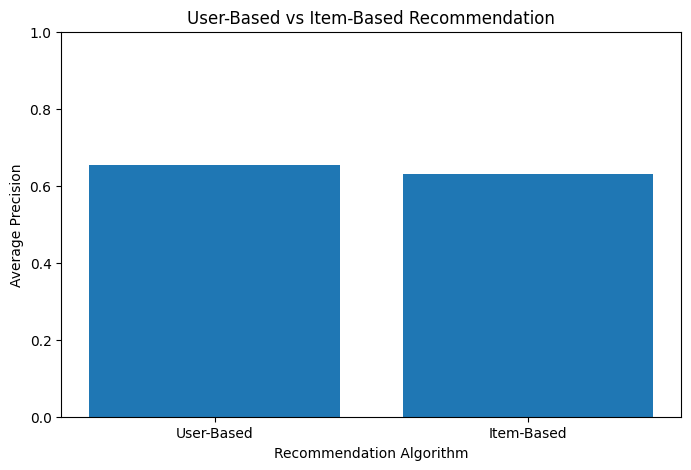

In [102]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.bar(
    comparison['Algorithm'],
    comparison['Average Precision']
)

plt.title('User-Based vs Item-Based Recommendation')
plt.xlabel('Recommendation Algorithm')
plt.ylabel('Average Precision')

plt.ylim(0, 1)

plt.show()

In [103]:
!pip install scikit-surprise

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 9.0 MB/s  0:00:00


In [104]:
from surprise import Dataset, Reader, SVD
from surprise.model_selection import train_test_split
from surprise import accuracy

In [105]:
svd_data = ratings[['user_id', 'movie_id', 'rating']].copy()

svd_data.head()

,user_id,movie_id,rating
0,196,242,3
1,186,302,3
2,22,377,1
3,244,51,2
4,166,346,1


In [106]:
from surprise import Dataset, Reader

reader = Reader(rating_scale=(1, 5))

In [107]:
data = Dataset.load_from_df(svd_data, reader)

In [108]:
from surprise.model_selection import train_test_split as surprise_train_test_split

svd_trainset, svd_testset = surprise_train_test_split(
    data,
    test_size=0.2,
    random_state=42
)

## Creating the svd model

In [109]:
from surprise import SVD

svd_model = SVD(
    n_factors=100,
    n_epochs=20,
    random_state=42
)

In [110]:
svd_model.fit(svd_trainset)

In [111]:
svd_predictions = svd_model.test(svd_testset)

from surprise import accuracy

svd_rmse = accuracy.rmse(svd_predictions)

svd_mae = accuracy.mae(svd_predictions)

RMSE: 0.9352
MAE:  0.7375


In [112]:
prediction = svd_model.predict(196, 50)

print("User ID:", prediction.uid)
print("Movie ID:", prediction.iid)
print("Predicted Rating:", prediction.est)

User ID: 196
Movie ID: 50
Predicted Rating: 4.437606074301294


In [113]:
print(f"Predicted rating: {prediction.est:.2f} / 5")


Predicted rating: 4.44 / 5


In [114]:
all_movie_ids = ratings['movie_id'].unique()

print("Total movies:", len(all_movie_ids))

Total movies: 1682


### Find movies User 196 hasn't rated

In [115]:
user_rated_movies = set(
    train_user_item_matrix.loc[196].dropna().index
)

unrated_movies = [
    movie_id
    for movie_id in all_movie_ids
    if movie_id not in user_rated_movies
]

print("Movies already rated:", len(user_rated_movies))
print("Movies not yet rated:", len(unrated_movies))

Movies already rated: 29
Movies not yet rated: 1653


### Predict ratings for unrated movies

In [116]:
svd_recommendations = []

for movie_id in unrated_movies:

    prediction = svd_model.predict(196, movie_id)

    svd_recommendations.append({
        'movie_id': movie_id,
        'predicted_rating': prediction.est
    })

In [117]:
svd_recommendations_df = pd.DataFrame(svd_recommendations)

svd_recommendations_df = svd_recommendations_df.sort_values(
    by='predicted_rating',
    ascending=False
)

svd_recommendations_df.head(10)

,movie_id,predicted_rating
197,318,4.643424
235,64,4.605962
4,474,4.578762
177,408,4.555358
236,357,4.537785
77,480,4.512972
516,511,4.500572
35,603,4.485682
48,100,4.484790
519,513,4.449329


In [120]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [122]:
import os

os.listdir('/content/drive/MyDrive/')

['20251212_212904.aac',
 'Audio from F.R.O',
 '20251212_212904.mp3',
 '20251213_005033.aac',
 '2.mp3',
 '1000768017.jpg',
 '1000768008.jpg',
 'Screenshot_20260310-213315.jpg',
 'assignment (1).xlsx',
 'ASS.xlsx',
 'assignment.xlsx',
 'RichardFajorin_InternshalaResume.pdf',
 'ROk for this give me a PDF I can use for all this ....gdoc',
 'IMG-20260525-WA0015.jpg',
 'IMG-20260528-WA0006.jpg',
 '20260529_205258.aac',
 'IMG-20260604-WA0095.jpg',
 'Waec certificate_compressed (1).pdf',
 'Waec certificate_compressed.pdf',
 'Origin certificate_compressed.pdf',
 'passport_compressed.pdf',
 'Birth certificate_compressed (1).pdf',
 'Birth certificate_compressed.pdf',
 'Admission letter_compressed (4).pdf',
 'Admission letter_compressed (3).pdf',
 'Admission letter_compressed (2).pdf',
 'Admission letter_compressed (1).pdf',
 'jamb score_compressed.pdf',
 'school id_compressed.pdf',
 'passport (1)_compressed (1).pdf',
 'passport (1)_compressed.pdf',
 'Colab Notebooks',
 'Richard Week1-2 Submission

In [123]:
for root, dirs, files in os.walk('/content/drive/MyDrive/'):
    if 'u.item' in files:
        print(os.path.join(root, 'u.item'))

In [124]:
import os

for root, dirs, files in os.walk('/content'):
    if 'u.item' in files:
        print(os.path.join(root, 'u.item'))

/content/u.item


In [125]:
movie_columns = [
    'movie_id', 'title', 'release_date', 'video_release_date', 'IMDb_URL',
    'unknown', 'Action', 'Adventure', 'Animation', 'Children', 'Comedy',
    'Crime', 'Documentary', 'Drama', 'Fantasy', 'Film-Noir', 'Horror',
    'Musical', 'Mystery', 'Romance', 'Sci-Fi', 'Thriller', 'War', 'Western'
]

movies = pd.read_csv(
    '/content/u.item',
    sep='|',
    encoding='latin-1',
    names=movie_columns
)

movies.head()

,movie_id,title,release_date,video_release_date,IMDb_URL,unknown,Action,Adventure,Animation,Children,...,Fantasy,Film-Noir,Horror,Musical,Mystery,Romance,Sci-Fi,Thriller,War,Western
0,1,Toy Story (1995),01-Jan-1995,NaN,http://us.imdb.com/M/title-exact?Toy%20Story%2...,0,0,0,1,1,...,0,0,0,0,0,0,0,0,0,0
1,2,GoldenEye (1995),01-Jan-1995,NaN,http://us.imdb.com/M/title-exact?GoldenEye%20(...,0,1,1,0,0,...,0,0,0,0,0,0,0,1,0,0
2,3,Four Rooms (1995),01-Jan-1995,NaN,http://us.imdb.com/M/title-exact?Four%20Rooms%...,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
3,4,Get Shorty (1995),01-Jan-1995,NaN,http://us.imdb.com/M/title-exact?Get%20Shorty%...,0,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,5,Copycat (1995),01-Jan-1995,NaN,http://us.imdb.com/M/title-exact?Copycat%20(1995),0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0


In [126]:
final_recommendations = svd_recommendations_df.merge(
    movies[['movie_id', 'title']],
    on='movie_id',
    how='left'
)

final_recommendations.head(10)

,movie_id,predicted_rating,title
0,318,4.643424,Schindler's List (1993)
1,64,4.605962,"Shawshank Redemption, The (1994)"
2,474,4.578762,Dr. Strangelove or: How I Learned to Stop Worr...
3,408,4.555358,"Close Shave, A (1995)"
4,357,4.537785,One Flew Over the Cuckoo's Nest (1975)
5,480,4.512972,North by Northwest (1959)
6,511,4.500572,Lawrence of Arabia (1962)
7,603,4.485682,Rear Window (1954)
8,100,4.484790,Fargo (1996)
9,513,4.449329,"Third Man, The (1949)"


In [127]:
def evaluate_svd(user_id, k=10):

    # Get movies rated by this user in the test dataset
    user_test = ratings_test[ratings_test['user_id'] == user_id]

    # If the user has no test ratings, return None
    if len(user_test) == 0:
        return None

    # Predict ratings for the user's test movies
    predictions = []

    for movie_id in user_test['movie_id']:
        prediction = svd_model.predict(user_id, movie_id)

        predictions.append({
            'movie_id': movie_id,
            'predicted_rating': prediction.est
        })

    # Convert predictions into a DataFrame
    predictions_df = pd.DataFrame(predictions)

    # Rank movies by predicted rating
    top_k = predictions_df.sort_values(
        by='predicted_rating',
        ascending=False
    ).head(k)

    # Identify relevant movies (actual rating >= 4)
    relevant_movies = set(
        user_test[user_test['rating'] >= 4]['movie_id']
    )

    # Count relevant recommendations
    relevant_recommended = sum(
        movie_id in relevant_movies
        for movie_id in top_k['movie_id']
    )

    # Calculate Precision@K
    precision = relevant_recommended / len(top_k)

    return precision

### Creating SVD DAtaframe

In [128]:
ratings_test = pd.DataFrame(
    svd_testset,
    columns=['user_id', 'movie_id', 'rating']
)

ratings_test.head()

,user_id,movie_id,rating
0,907,143,5.0
1,371,210,4.0
2,218,42,4.0
3,829,170,4.0
4,733,277,1.0


In [129]:
svd_precision = evaluate_svd(196, k=10)

print("SVD Precision@10:", svd_precision)

SVD Precision@10: 0.42857142857142855


In [130]:
len(ratings_test[ratings_test['user_id'] == 196])

7

### Across Multiple Users

In [131]:
svd_results = []

for user_id in ratings_test['user_id'].unique():

    user_count = len(
        ratings_test[ratings_test['user_id'] == user_id]
    )

    if user_count >= 10:
        score = evaluate_svd(user_id, k=10)

        svd_results.append({
            'user_id': user_id,
            'precision_at_10': score
        })

svd_evaluation = pd.DataFrame(svd_results)

print("Users evaluated:", len(svd_evaluation))
print("Average SVD Precision@10:",
      svd_evaluation['precision_at_10'].mean())

Users evaluated: 583
Average SVD Precision@10: 0.725557461406518


In [132]:
comparison = pd.DataFrame({
    'Algorithm': [
        'User-Based',
        'Item-Based',
        'SVD'
    ],
    'Average Precision': [
        0.653589,
        0.629312,
        0.725557
    ]
})

comparison

,Algorithm,Average Precision
0,User-Based,0.653589
1,Item-Based,0.629312
2,SVD,0.725557


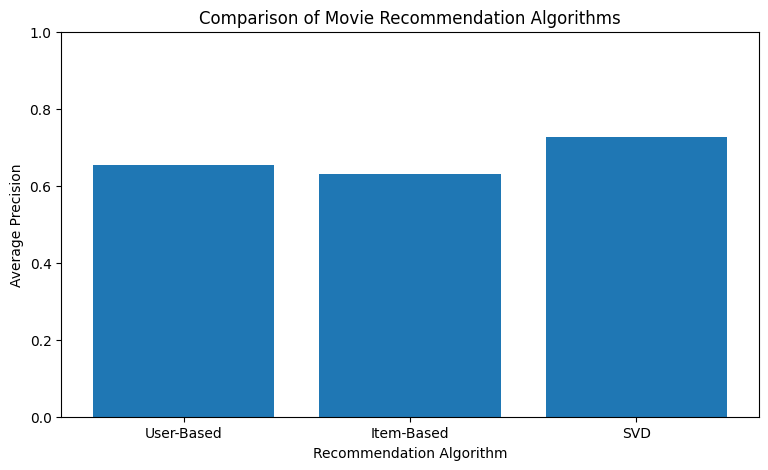

In [133]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.bar(
    comparison['Algorithm'],
    comparison['Average Precision']
)

plt.title('Comparison of Movie Recommendation Algorithms')
plt.xlabel('Recommendation Algorithm')
plt.ylabel('Average Precision')
plt.ylim(0, 1)

plt.show()

### Create a shared evaluation dataset

In [134]:
print("Training data:", train_data.shape)
print("Testing data:", test_data.shape)

print("Training users:", train_data['user_id'].nunique())
print("Testing users:", test_data['user_id'].nunique())

Training data: (80000, 4)
Testing data: (20000, 4)
Training users: 943
Testing users: 940


In [135]:
from surprise import Dataset, Reader, SVD, accuracy

# Prepare the training data
reader = Reader(rating_scale=(1, 5))

svd_train_data = Dataset.load_from_df(
    train_data[['user_id', 'movie_id', 'rating']],
    reader
)

# Train the model
svd_trainset = svd_train_data.build_full_trainset()

svd_model = SVD(
    n_factors=100,
    n_epochs=20,
    random_state=42
)

svd_model.fit(svd_trainset)

print("SVD training completed!")

SVD training completed!


In [136]:
# Convert the test data into Surprise's required format
svd_testset = list(
    test_data[['user_id', 'movie_id', 'rating']]
    .itertuples(index=False, name=None)
)

# Generate predictions
svd_predictions = svd_model.test(svd_testset)

# Calculate evaluation metrics
svd_rmse = accuracy.rmse(svd_predictions)
svd_mae = accuracy.mae(svd_predictions)

RMSE: 0.9346
MAE:  0.7376


In [138]:
def evaluate_svd_shared(user_id, k=10):

    user_test = test_data[
        test_data['user_id'] == user_id
    ]

    if len(user_test) < k:
        return None

    predictions = []

    for _, row in user_test.iterrows():
        prediction = svd_model.predict(
            row['user_id'],
            row['movie_id']
        )

        predictions.append({
            'movie_id': row['movie_id'],
            'predicted_rating': prediction.est,
            'actual_rating': row['rating']
        })

    predictions_df = pd.DataFrame(predictions)

    top_k = predictions_df.sort_values(
        'predicted_rating',
        ascending=False
    ).head(k)

    relevant = (top_k['actual_rating'] >= 4).sum()

    return relevant / k

In [139]:
svd_shared_results = []

for user_id in test_data['user_id'].unique():

    score = evaluate_svd_shared(user_id, k=10)

    if score is not None:
        svd_shared_results.append({
            'user_id': user_id,
            'precision_at_10': score
        })

svd_shared_evaluation = pd.DataFrame(svd_shared_results)

print("Users evaluated:", len(svd_shared_evaluation))

print(
    "Average SVD Precision@10:",
    svd_shared_evaluation['precision_at_10'].mean()
)

Users evaluated: 580
Average SVD Precision@10: 0.7248275862068965


In [140]:
def evaluate_user_shared(user_id, k=10):

    user_test = test_data[
        test_data['user_id'] == user_id
    ]

    if len(user_test) < k:
        return None

    if user_id not in train_user_similarity_df.index:
        return None

    similar_users = train_user_similarity_df[user_id].drop(
        user_id, errors='ignore'
    ).nlargest(10)

    scores = {}

    for movie_id in user_test['movie_id']:

        if movie_id not in train_user_item_matrix.columns:
            continue

        ratings_by_neighbors = train_user_item_matrix.loc[
            similar_users.index, movie_id
        ].dropna()

        if len(ratings_by_neighbors) == 0:
            continue

        scores[movie_id] = ratings_by_neighbors.mean()

    if len(scores) < k:
        return None

    top_movies = sorted(
        scores,
        key=scores.get,
        reverse=True
    )[:k]

    relevant_movies = set(
        user_test[user_test['rating'] >= 4]['movie_id']
    )

    hits = sum(movie in relevant_movies for movie in top_movies)

    return hits / k

In [141]:
user_shared_results = []

for user_id in test_data['user_id'].unique():

    score = evaluate_user_shared(user_id, k=10)

    if score is not None:
        user_shared_results.append({
            'user_id': user_id,
            'precision_at_10': score
        })

user_shared_evaluation = pd.DataFrame(user_shared_results)

print("Users evaluated:", len(user_shared_evaluation))

print(
    "Average User-Based Precision@10:",
    user_shared_evaluation['precision_at_10'].mean()
)

Users evaluated: 539
Average User-Based Precision@10: 0.7076066790352505


### Evaluate Item-Based filtering

In [142]:
def evaluate_item_shared(user_id, k=10):

    user_test = test_data[
        test_data['user_id'] == user_id
    ]

    if len(user_test) < k:
        return None

    if user_id not in train_user_item_matrix.index:
        return None

    user_ratings = train_user_item_matrix.loc[user_id].dropna()

    liked_movies = user_ratings[user_ratings >= 4]

    if liked_movies.empty:
        return None

    scores = {}

    for movie_id in user_test['movie_id']:

        if movie_id not in item_similarity_df.index:
            continue

        similarities = item_similarity_df.loc[
            movie_id, liked_movies.index
        ]

        weighted_score = (
            similarities * liked_movies
        ).sum()

        similarity_total = similarities.sum()

        if similarity_total > 0:
            scores[movie_id] = weighted_score / similarity_total

    if len(scores) < k:
        return None

    top_movies = sorted(
        scores,
        key=scores.get,
        reverse=True
    )[:k]

    relevant_movies = set(
        user_test[user_test['rating'] >= 4]['movie_id']
    )

    hits = sum(
        movie in relevant_movies for movie in top_movies
    )

    return hits / k

In [143]:
item_shared_results = []

for user_id in test_data['user_id'].unique():

    score = evaluate_item_shared(user_id, k=10)

    if score is not None:
        item_shared_results.append({
            'user_id': user_id,
            'precision_at_10': score
        })

item_shared_evaluation = pd.DataFrame(item_shared_results)

print("Users evaluated:", len(item_shared_evaluation))

print(
    "Average Item-Based Precision@10:",
    item_shared_evaluation['precision_at_10'].mean()
)

Users evaluated: 580
Average Item-Based Precision@10: 0.6577586206896552


In [144]:
comparison = pd.DataFrame({
    'Algorithm': [
        'User-Based',
        'Item-Based',
        'SVD'
    ],
    'Average Precision': [
        user_shared_evaluation['precision_at_10'].mean(),
        item_shared_evaluation['precision_at_10'].mean(),
        svd_shared_evaluation['precision_at_10'].mean()
    ]
})

comparison

,Algorithm,Average Precision
0,User-Based,0.707607
1,Item-Based,0.657759
2,SVD,0.724828


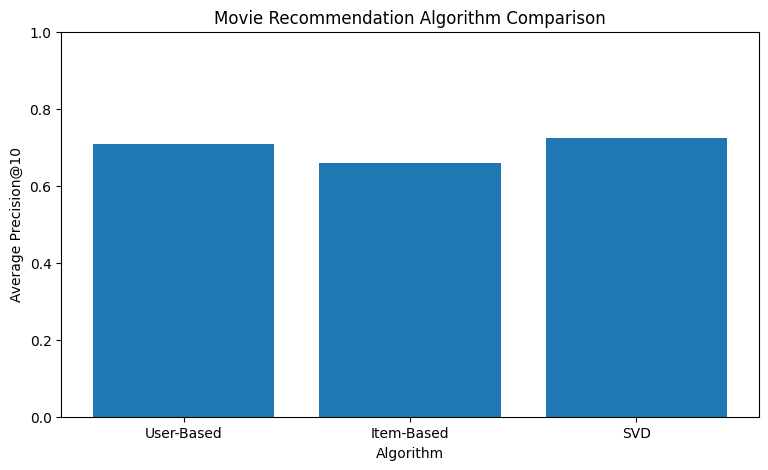

In [145]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.bar(
    comparison['Algorithm'],
    comparison['Average Precision']
)

plt.title('Movie Recommendation Algorithm Comparison')
plt.xlabel('Algorithm')
plt.ylabel('Average Precision@10')
plt.ylim(0, 1)

plt.show()